**Dự đoán nguy cơ đột quỵ sử dụng mô hình học máy dựa trên dữ liệu y tế**

In [1]:
!pip install h2o

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 MB 5.9 MB/s eta 0:00:00


In [2]:
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.mosaicplot import mosaic
import h2o
from h2o.estimators import H2ORandomForestEstimator
from h2o.estimators import H2OGradientBoostingEstimator

# **Nhập dữ liệu**

In [3]:
# load data
df = pd.read_csv('/content/healthcare-dataset-stroke-data.csv')

In [4]:
# dimensions of data
df.shape

(5110, 12)

In [5]:
# column names
print(df.columns.tolist())

['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']


In [6]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


# **Làm sạch dữ liệu**

In [7]:
# overview of data structure
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


**BMI value!**

In [8]:
# impute with -99
df.bmi = df.bmi.fillna(-99)

In [9]:
# rename columns
df.rename(columns = {'Residence_type':'residence_type'}, inplace = True)

In [10]:
# define target variable
df['target'] = df.stroke
df = df.drop(['stroke'], axis=1) # remove stroke column

# **Tính năng số**

In [11]:
# select numerical features
features_num = ['age', 'avg_glucose_level','bmi']

In [12]:
# basic stats
df[features_num].describe(percentiles=[0.1,0.25,0.5,0.75,0.9])

,age,avg_glucose_level,bmi
count,5110.000000,5110.000000,5110.000000
mean,43.226614,106.147677,23.862603
std,22.612647,45.283560,26.028009
min,0.080000,55.120000,-99.000000
10%,11.000000,65.789000,18.290000
25%,25.000000,77.245000,22.900000
50%,45.000000,91.885000,27.700000
75%,61.000000,114.090000,32.800000
90%,75.000000,192.181000,38.700000
max,82.000000,271.740000,97.600000


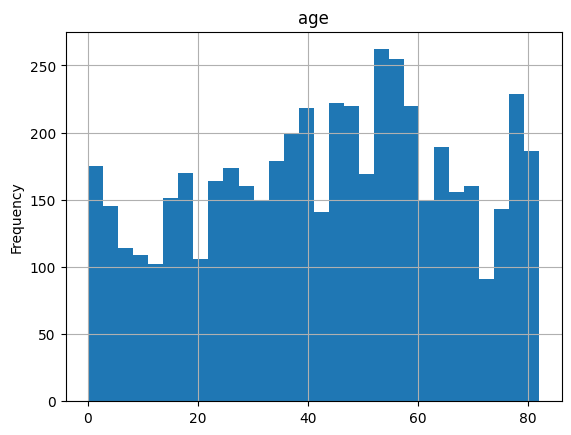

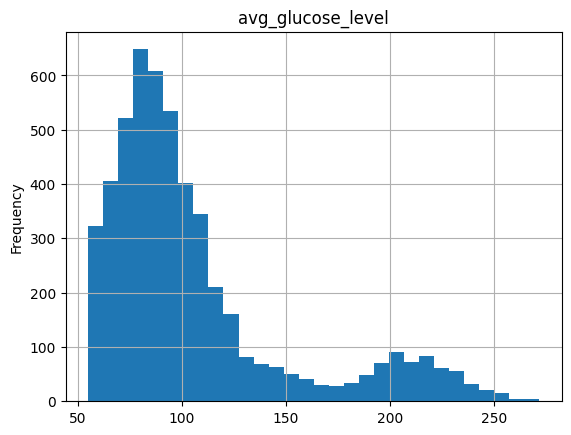

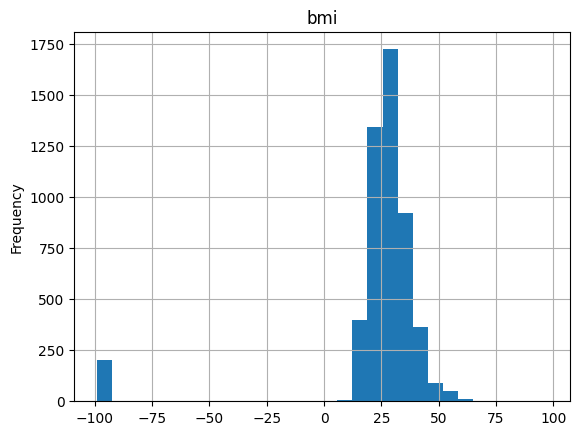

In [13]:
# plot distribution of numerical features
for f in features_num:
    df[f].plot(kind='hist', bins=30)
    plt.title(f)
    plt.grid()
    plt.show()

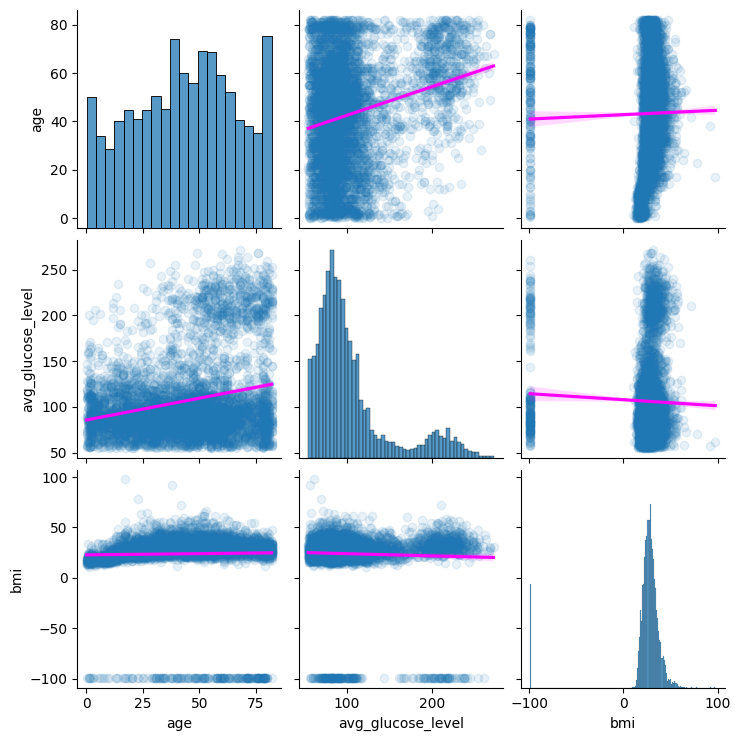

In [14]:
# pairwise scatter plot
sns.pairplot(df[features_num],
             kind='reg',
             plot_kws={'line_kws':{'color':'magenta'}, 'scatter_kws': {'alpha': 0.1}})
plt.show()

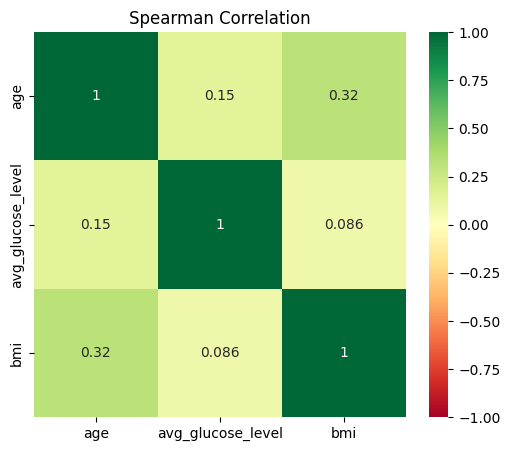

In [15]:
# Spearman (Rank) correlation
corr_spearman = df[features_num].corr(method='spearman')

fig = plt.figure(figsize = (6,5))
sns.heatmap(corr_spearman, annot=True, cmap="RdYlGn", vmin=-1, vmax=+1)
plt.title('Spearman Correlation')
plt.show()

# **Tính năng phân loại**

In [16]:
features_cat = ['gender','hypertension','heart_disease','ever_married',
                'work_type','residence_type','smoking_status']

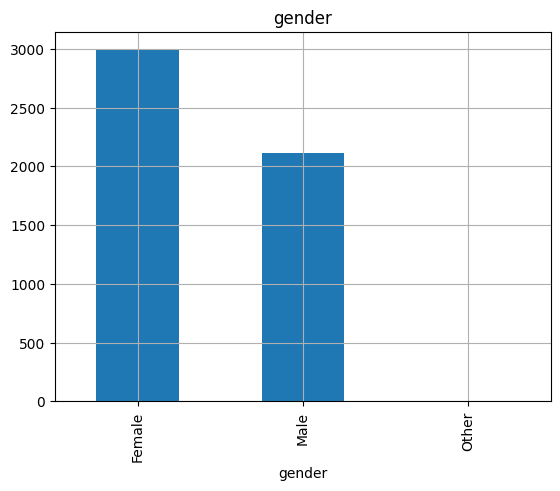

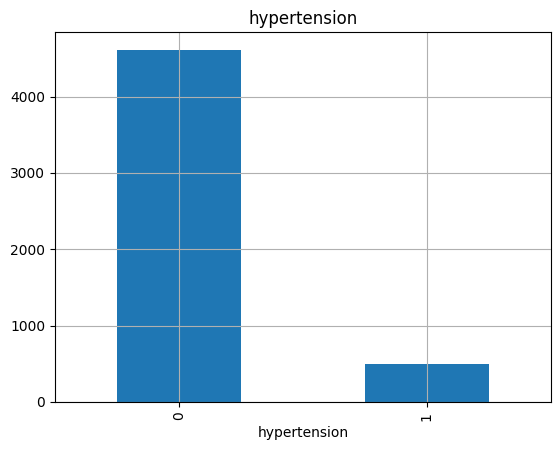

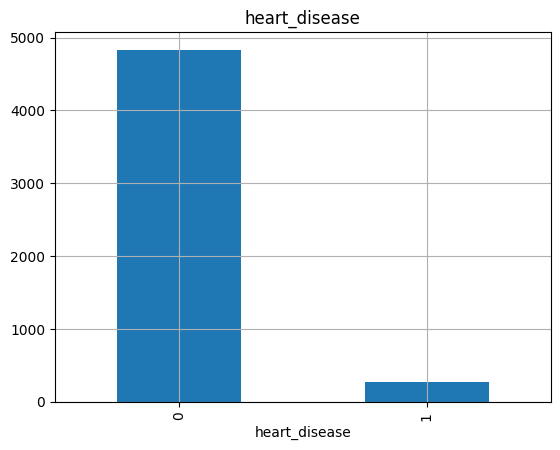

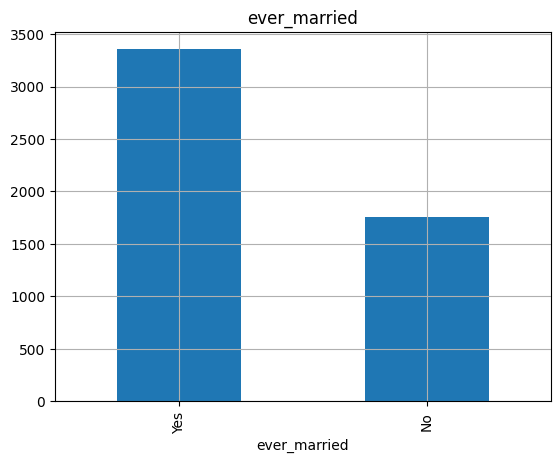

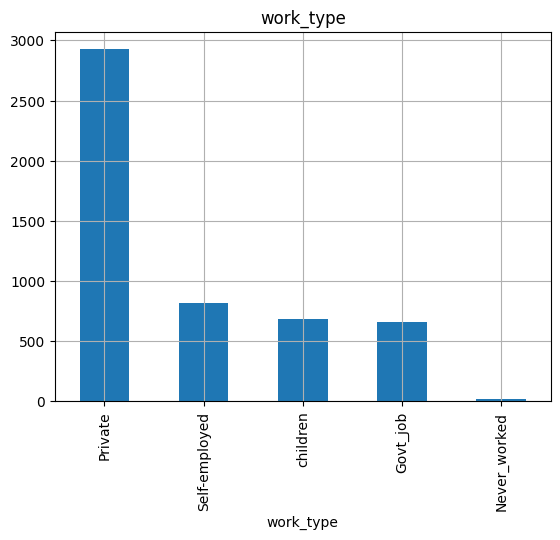

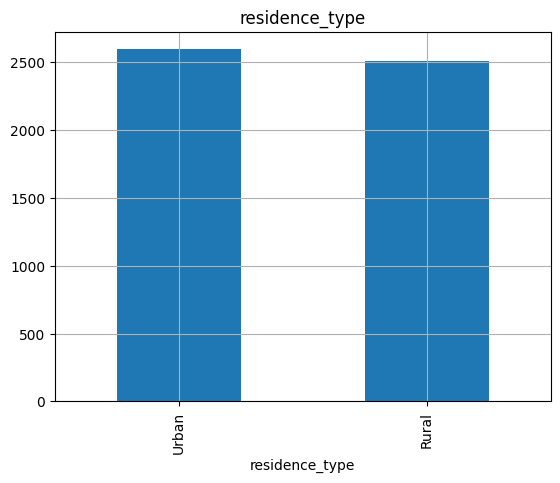

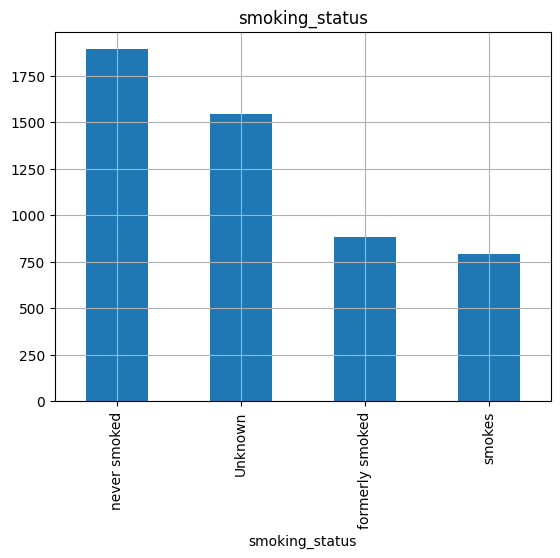

In [17]:
# plot distribution of categorical features
for f in features_cat:
    df[f].value_counts().plot(kind='bar')
    plt.title(f)
    plt.grid()
    plt.show()

# **Mục tiêu**

In [18]:
# calc frequencies
target_count = df.target.value_counts()
print(target_count)
print()
print('Percentage of strokes [1]:', np.round(100*target_count[1] / target_count.sum(),2), '%')

target
0    4861
1     249
Name: count, dtype: int64

Percentage of strokes [1]: 4.87 %


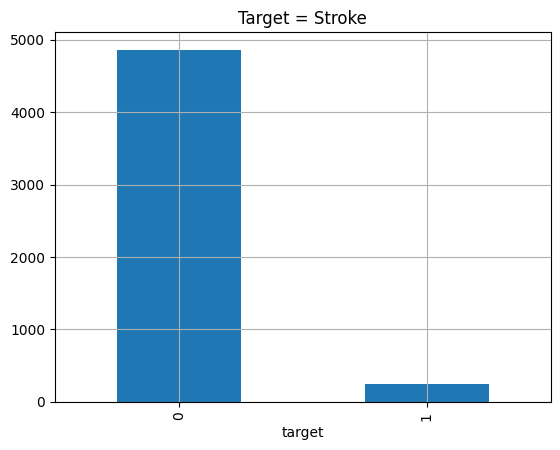

In [19]:
# plot target distribution
target_count.plot(kind='bar')
plt.title('Target = Stroke')
plt.grid()
plt.show()

# **Mục tiêu so với các tính năng số**

In [20]:
# add binned version of numerical features

# quantile based:
df['age_bin'] = pd.qcut(df['age'], q=10, precision=1)
df['avg_glucose_level_bin'] = pd.qcut(df['avg_glucose_level'], q=10, precision=1)

# explicitly defined bins:
df['bmi_bin'] = pd.cut(df['bmi'], [-100,10,20,25,30,35,40,50,100])

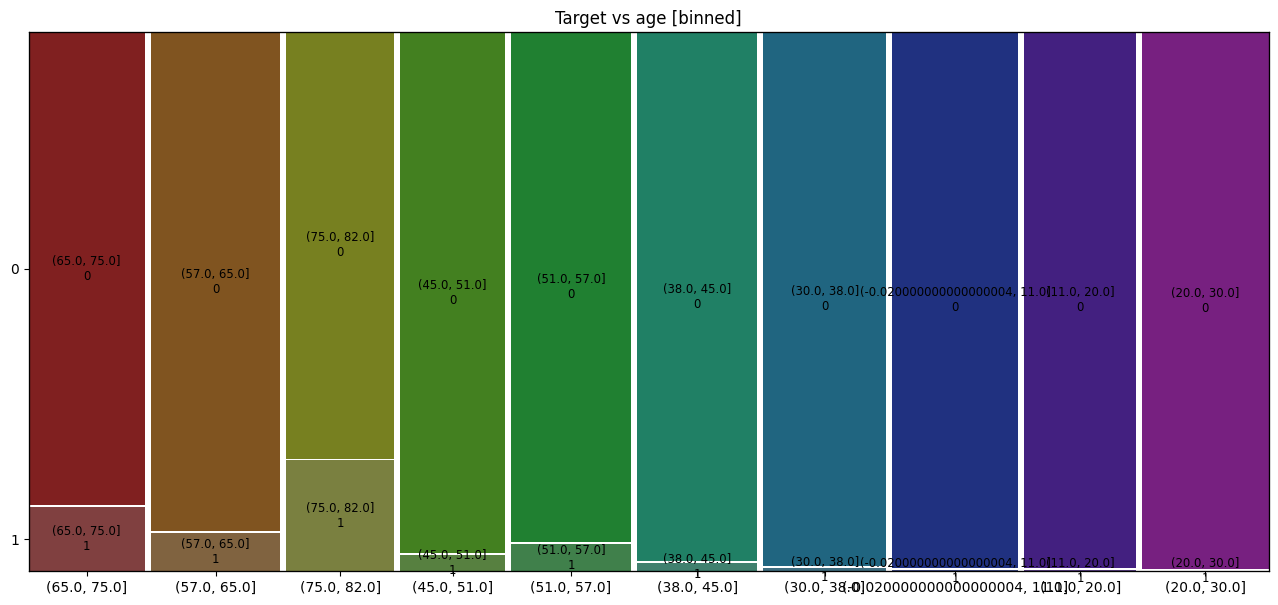

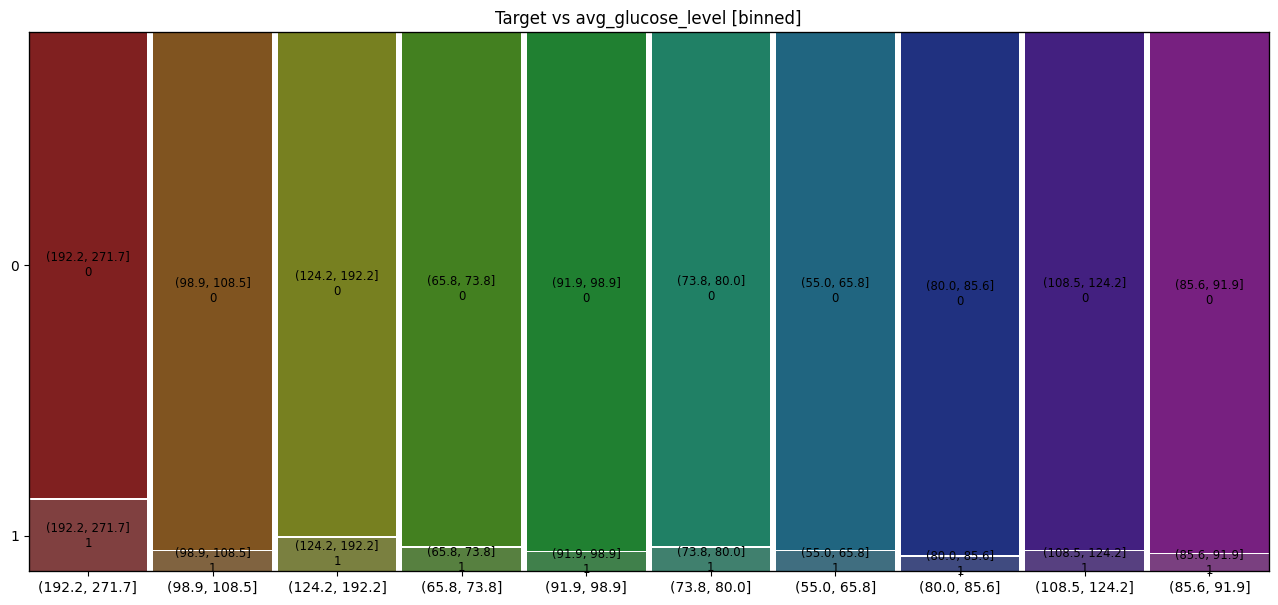

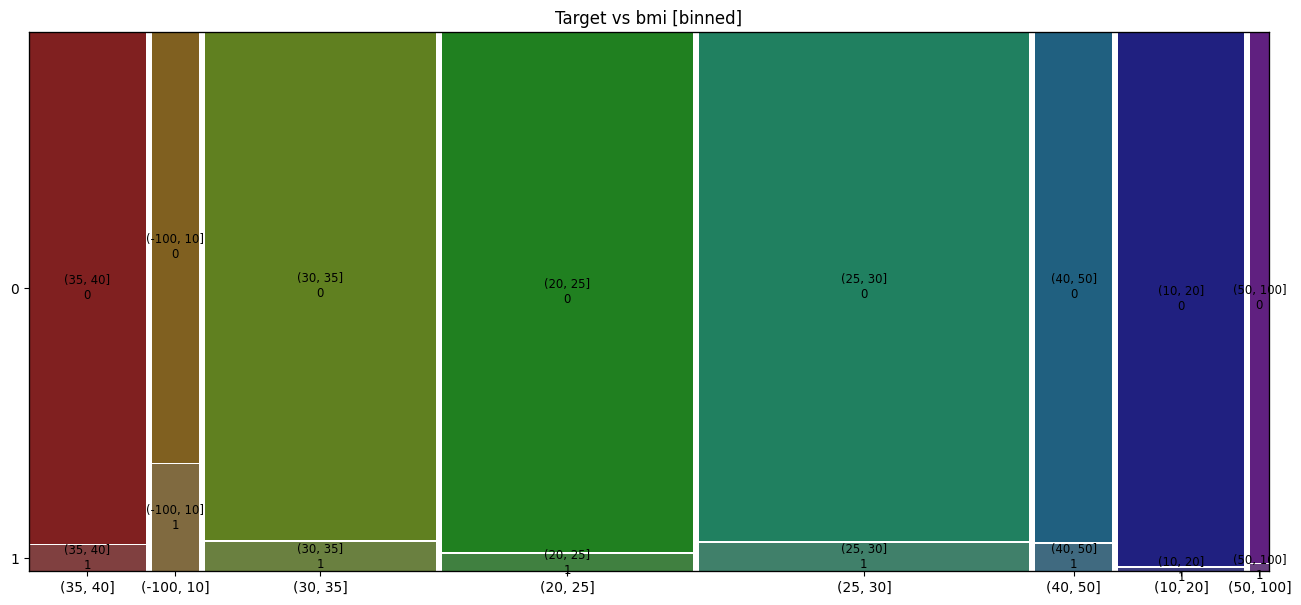

In [21]:
# plot target vs features using mosaic plot
plt_para_save = plt.rcParams['figure.figsize'] # remember plot settings

for f in features_num:
    f_bin = f+'_bin'
    plt.rcParams["figure.figsize"] = (16,7) # increase plot size for mosaics
    mosaic(df, [f_bin, 'target'], title='Target vs ' + f + ' [binned]')
    plt.show()

# reset plot size again
plt.rcParams['figure.figsize'] = plt_para_save

**Nguy cơ tăng theo tuổi và mức glucose (bệnh tiểu đường).**

**Mức BMI cao cũng chỉ ra nguy cơ cao hơn.**

**Một giá trị BMI bị thiếu (cột ngoài cùng bên trái) dường như chỉ ra nguy cơ tăng đáng kể!**

In [22]:
# BMI - check cross table
ctab = pd.crosstab(df.bmi_bin, df.target)
ctab

target,0,1
bmi_bin,,
"(-100, 10]",161,40
"(10, 20]",534,3
"(20, 25]",1035,35
"(25, 30]",1334,75
"(30, 35]",931,54
"(35, 40]",476,24
"(40, 50]",312,17
"(50, 100]",78,1


In [23]:
# normalize each row to get row-wise target percentages
(ctab.transpose() / ctab.sum(axis=1)).transpose()

target,0,1
bmi_bin,,
"(-100, 10]",0.800995,0.199005
"(10, 20]",0.994413,0.005587
"(20, 25]",0.967290,0.032710
"(25, 30]",0.946771,0.053229
"(30, 35]",0.945178,0.054822
"(35, 40]",0.952000,0.048000
"(40, 50]",0.948328,0.051672
"(50, 100]",0.987342,0.012658


 **Gần 20% BMI bị mất là do đột quỵ! Con số này cao hơn nhiều so với các nhóm khác.**

# **Tính năng mục tiêu so với tính năng danh mục**

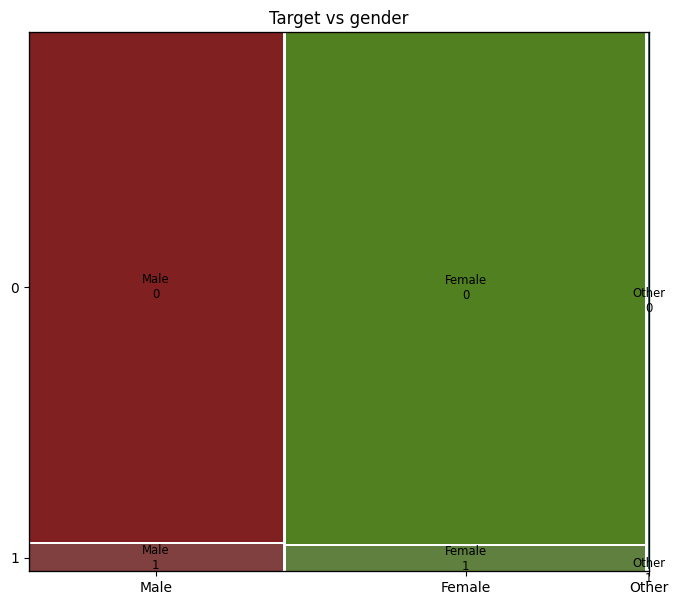

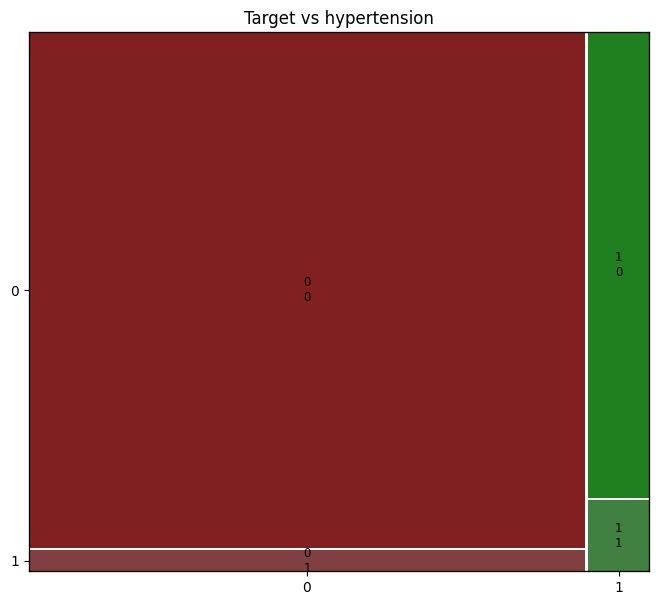

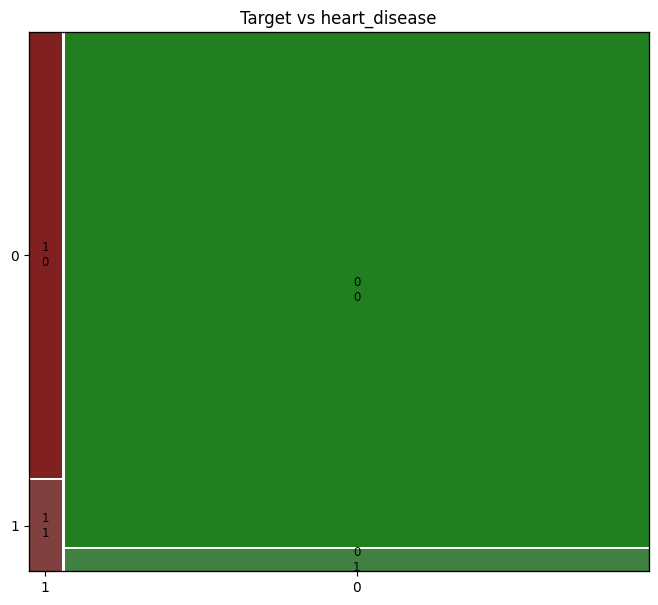

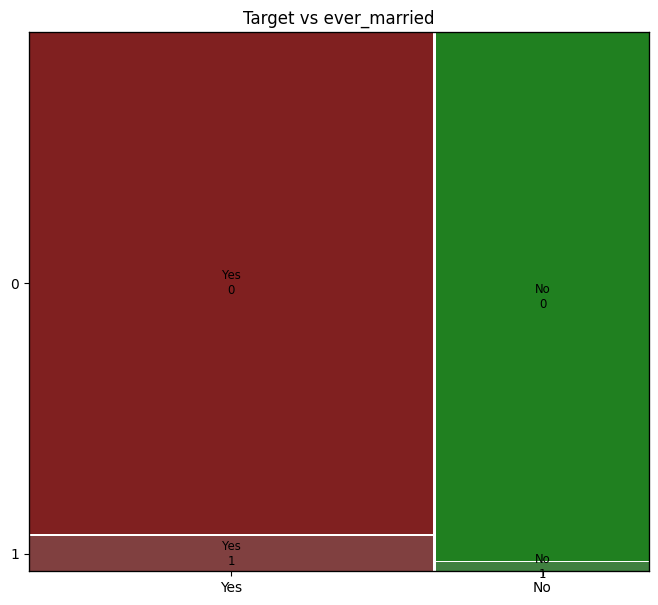

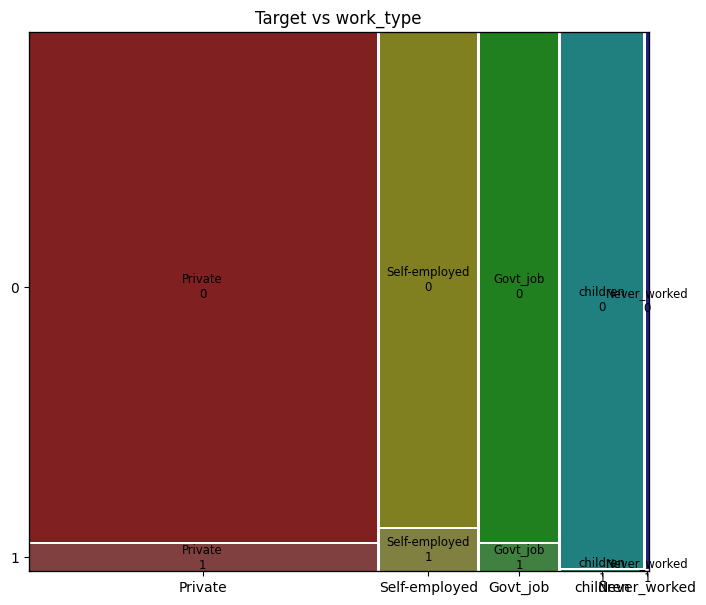

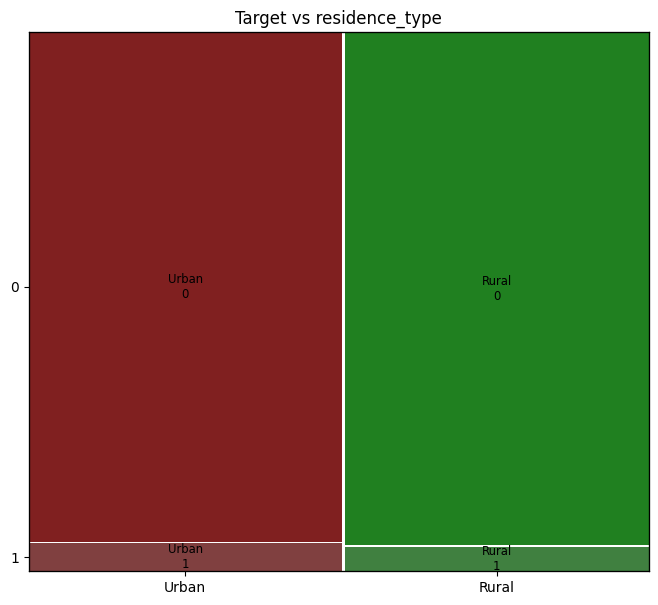

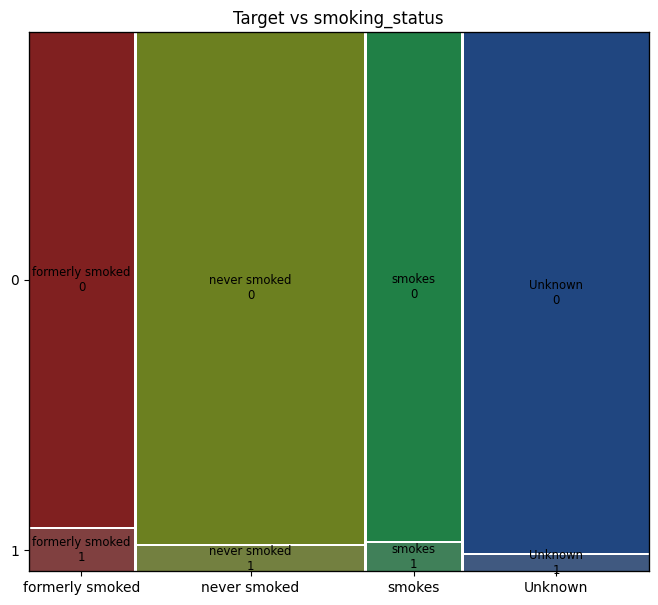

In [24]:
# plot target vs features using mosaic plot
plt_para_save = plt.rcParams['figure.figsize'] # remember plot settings

for f in features_cat:
    plt.rcParams["figure.figsize"] = (8,7) # increase plot size for mosaics
    mosaic(df, [f, 'target'], title='Target vs ' + f)
    plt.show()

# reset plot size again
plt.rcParams['figure.figsize'] = plt_para_save

**Ảnh hưởng của giới tính có vẻ thấp một cách đáng ngạc nhiên**

**Tăng huyết áp và bệnh tim làm tăng đáng kể nguy cơ đột quỵ "Đã từng kết hôn" nữa sao!?**

**Loại công việc: Nguy cơ cao hơn đối với người tự kinh doanh (căng thẳng hơn?)**

**Loại nơi cư trú: Nguy cơ cao hơn một chút đối với người thành thị so với nông thôn**

**Hút thuốc: Nguy cơ cao nhất đối với người đã từng hút thuốc. Không có nhiều sự khác biệt giữa "hút thuốc" và "chưa từng hút thuốc"?**

In [25]:
# "ever married" - check cross table
ctab = pd.crosstab(df.ever_married, df.target)
ctab

target,0,1
ever_married,,
No,1728,29
Yes,3133,220


In [26]:
# normalize each row
(ctab.transpose() / ctab.sum(axis=1)).transpose()

target,0,1
ever_married,,
No,0.983495,0.016505
Yes,0.934387,0.065613


# **Xây dựng mô hình**

In [27]:
# select predictors
predictors = features_num + features_cat
print('Number of predictors: ', len(predictors))
print(predictors)

Number of predictors:  10
['age', 'avg_glucose_level', 'bmi', 'gender', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'residence_type', 'smoking_status']


In [28]:
# start H2O
h2o.init(max_mem_size='12G', nthreads=4) # Use maximum of 12 GB RAM and 4 cores

Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
  Java Version: openjdk version "11.0.28" 2025-07-15; OpenJDK Runtime Environment (build 11.0.28+6-post-Ubuntu-1ubuntu122.04.1); OpenJDK 64-Bit Server VM (build 11.0.28+6-post-Ubuntu-1ubuntu122.04.1, mixed mode, sharing)
  Starting server from /usr/local/lib/python3.12/dist-packages/h2o/backend/bin/h2o.jar
  Ice root: /tmp/tmpbpjq_vz9
  JVM stdout: /tmp/tmpbpjq_vz9/h2o_unknownUser_started_from_python.out
  JVM stderr: /tmp/tmpbpjq_vz9/h2o_unknownUser_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.
Please download and install the latest version from: https://h2o-release.s3.amazonaws.com/h2o/latest_stable.html


H2O_cluster_uptime:,02 secs
H2O_cluster_timezone:,Etc/UTC
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.7
H2O_cluster_version_age:,4 months and 26 days
H2O_cluster_name:,H2O_from_python_unknownUser_qcxmu9
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,12 Gb
H2O_cluster_total_cores:,2
H2O_cluster_allowed_cores:,2
H2O_cluster_status:,"locked, healthy"


In [29]:
# upload data frame in H2O environment
# Convert gender to string type to potentially avoid issues with shap_summary_plot
df['gender'] = df['gender'].astype(str)

df_hex = h2o.H2OFrame(df)

# convert target to categorical
df_hex['target'] = df_hex['target'].asfactor()

# train / test split (70/30)
train_hex, test_hex = df_hex.split_frame(ratios=[0.7], seed=999)

# pandas versions of train/test
df_train = train_hex.as_data_frame()
df_test = test_hex.as_data_frame()

Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%


/usr/local/lib/python3.12/dist-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"
/usr/local/lib/python3.12/dist-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


In [30]:
# export for potential external processing
df_train.to_csv('df_train.csv')
df_test.to_csv('df_test.csv')

In [31]:
# define Gradient Boosting model
fit_1 = H2OGradientBoostingEstimator(ntrees = 100,
                                     max_depth=4,
                                     min_rows=10,
                                     learn_rate=0.01, # default: 0.1
                                     sample_rate=1,
                                     col_sample_rate=0.7,
                                     nfolds=5,
                                     score_each_iteration=True,
                                     stopping_metric='auto',
                                     stopping_rounds=10,
                                     seed=999)

In [32]:
# train model
t1 = time.time()
fit_1.train(x=predictors,
            y='target',
            training_frame=train_hex)
t2 = time.time()
print('Elapsed time [s]: ', np.round(t2-t1,2))

gbm Model Build progress: |██████████████████████████████████████████████████████| (done) 100%
Elapsed time [s]:  21.06


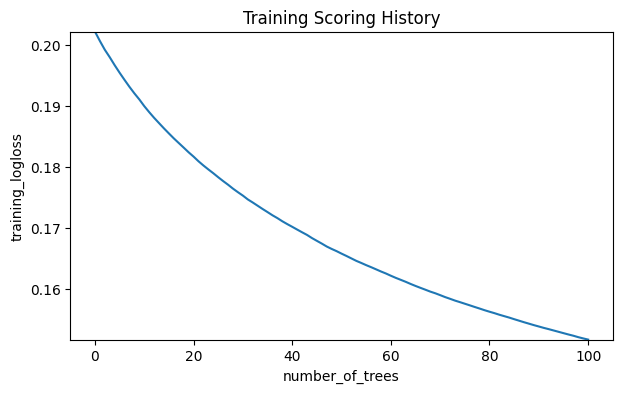

In [33]:
# show training scoring history
plt.rcParams['figure.figsize']=(7,4)
fit_1.plot()

In [34]:
# show cross validation metrics
fit_1.cross_validation_metrics_summary()

,mean,sd,cv_1_valid,cv_2_valid,cv_3_valid,cv_4_valid,cv_5_valid
accuracy,0.8829624,0.0268930,0.8985314,0.8645418,0.920904,0.8767313,0.8541033
aic,nan,0.0,nan,nan,nan,nan,nan
auc,0.8447821,0.0157750,0.8248061,0.8530365,0.8665343,0.8413103,0.8382235
err,0.1170376,0.0268930,0.1014686,0.1354582,0.0790960,0.1232687,0.1458967
err_count,83.8,18.308468,76.0,102.0,56.0,89.0,96.0
f0point5,0.2743523,0.0479990,0.2827381,0.2469136,0.3546099,0.2375,0.25
f1,0.3386312,0.0453714,0.3333333,0.32,0.4166667,0.2992126,0.3239437
f2,0.4459668,0.0421307,0.4059829,0.4545455,0.5050505,0.4042553,0.46
lift_top_group,8.911059,4.9263487,14.04375,4.9539475,10.411765,12.534722,2.6111112
loglikelihood,nan,0.0,nan,nan,nan,nan,nan


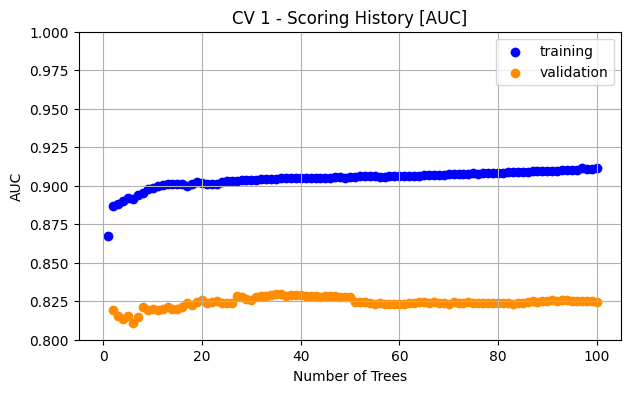

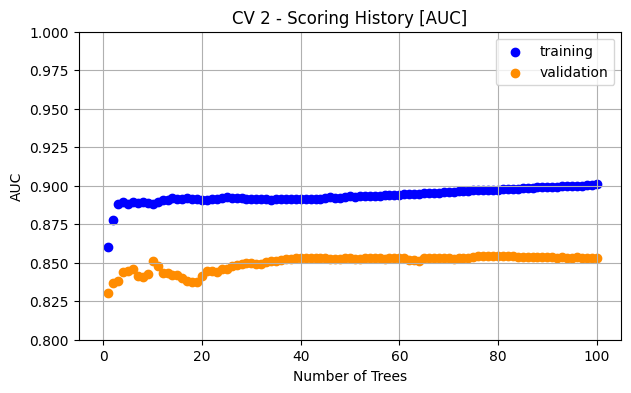

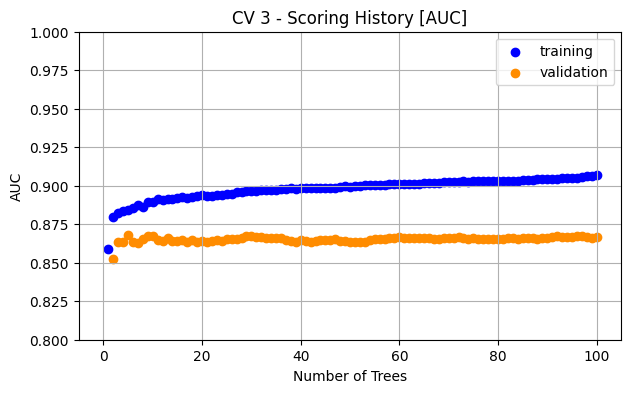

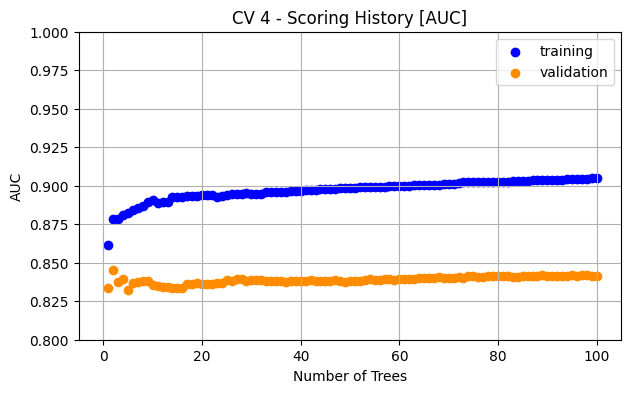

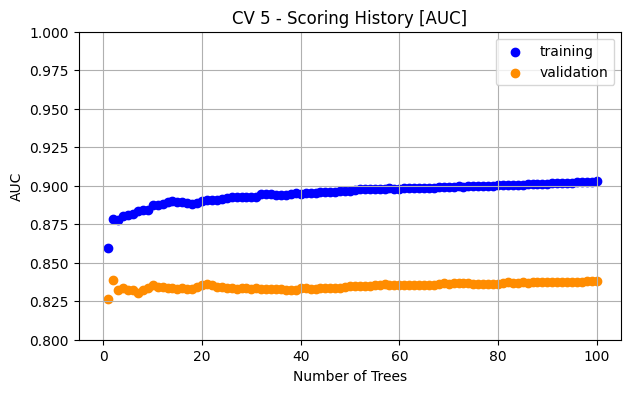

In [35]:
# show scoring history - training vs cross validations
for i in range(5):
    cv_model_temp = fit_1.cross_validation_models()[i]
    df_cv_score_history = cv_model_temp.score_history()
    my_title = 'CV ' + str(1+i) + ' - Scoring History [AUC]'
    plt.scatter(df_cv_score_history.number_of_trees,
                y=df_cv_score_history.training_auc,
                c='blue', label='training')
    plt.scatter(df_cv_score_history.number_of_trees,
                y=df_cv_score_history.validation_auc,
                c='darkorange', label='validation')
    plt.title(my_title)
    plt.xlabel('Number of Trees')
    plt.ylabel('AUC')
    plt.ylim(0.8,1)
    plt.legend()
    plt.grid()
    plt.show()

# **Đánh giá trên dữ liệu đào tạo**

### Đường cong ROC - Dữ liệu đào tạo

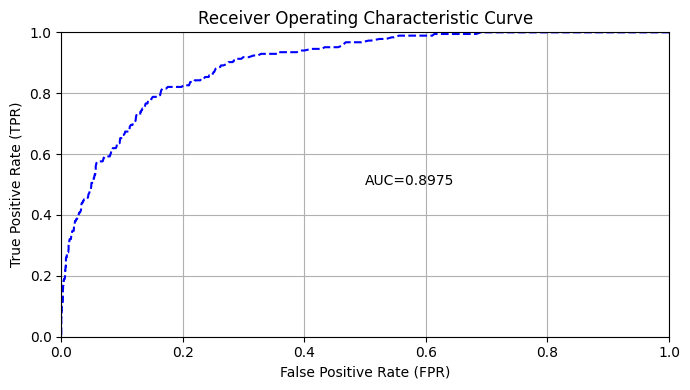

([0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0002935995302407516,
  0.0002935995302407516,
  0.0005871990604815032,
  0.0005871990604815032,
  0.0005871990604815032,
  0.0005871990604815032,
  0.0008807985907222549,
  0.0008807985907222549,
  0.0008807985907222549,
  0.0008807985907222549,
  0.0011743981209630064,
  0.001467997651203758,
  0.001467997651203758,
  0.001467997651203758,
  0.0017615971814445098,
  0.002055196711685261,
  0.002348796241926013,
  0.0026423957721667646,
  0.0026423957721667646,
  0.0026423957721667646,
  0.0026423957721667646,
  0.0026423957721667646,
  0.0026423957721667646,
  0.002935995302407516,
  0.002935995302407516,
  0.002935995302407516,
  0.0035231943628890195,
  0.0035231943628890195,
  0.0035231943628890195,
  0.003816793893129771,
  0.003816793893129771,
  0.004110393423370522,
  0.004697592483852026,
  0.0049911920140927775,
  0.005578391074574281,
  0.005871990604815032,
  0.0064591896652965355,
  0.00645918

In [36]:
# training performance
perf_train = fit_1.model_performance(train=True)
perf_train.plot()

## Đường cong ROC - Xác thực chéo

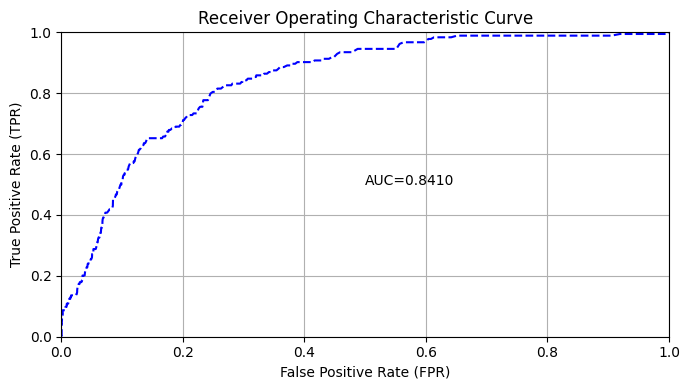

([0.0002935995302407516,
  0.0002935995302407516,
  0.0005871990604815032,
  0.0005871990604815032,
  0.0005871990604815032,
  0.0005871990604815032,
  0.0005871990604815032,
  0.0005871990604815032,
  0.0005871990604815032,
  0.0005871990604815032,
  0.0008807985907222549,
  0.0008807985907222549,
  0.0008807985907222549,
  0.0011743981209630064,
  0.0011743981209630064,
  0.0011743981209630064,
  0.001467997651203758,
  0.0017615971814445098,
  0.0017615971814445098,
  0.002055196711685261,
  0.002055196711685261,
  0.002348796241926013,
  0.002348796241926013,
  0.002348796241926013,
  0.002935995302407516,
  0.0032295948326482677,
  0.0035231943628890195,
  0.003816793893129771,
  0.004403992953611274,
  0.004697592483852026,
  0.0049911920140927775,
  0.005284791544333529,
  0.005578391074574281,
  0.005871990604815032,
  0.006165590135055784,
  0.006165590135055784,
  0.006752789195537287,
  0.006752789195537287,
  0.007339988256018791,
  0.007633587786259542,
  0.008220786846741

In [37]:
# cross validation performance
perf_cv = fit_1.model_performance(xval=True)
perf_cv.plot()

### Ma trận nhầm lẫn

In [38]:
# on training data - automatic threshold (optimal F1 score)
conf_train = fit_1.confusion_matrix(train=True)
conf_train.show()

,0,1,Error,Rate
0,3209.0,197.0,0.0578,(197.0/3406.0)
1,79.0,105.0,0.4293,(79.0/184.0)
Total,3288.0,302.0,0.0769,(276.0/3590.0)


In [39]:
# corresponding accuracy for this threshold:
conf_list_temp = conf_train.to_list()
n_matrix = sum(conf_list_temp[0]) + sum(conf_list_temp[1])
acc_t0 = (conf_list_temp[0][0]+conf_list_temp[1][1]) / n_matrix
print('Accuracy:', np.round(acc_t0,6))

Accuracy: 0.92312


### Việc chọn ngưỡng theo F1 tối ưu thực sự không hữu ích ở đây, chúng ta có sự khác biệt lớn giữa các giá trị dương thực tế (184) và các giá trị dương dự đoán (302). Hãy thử cải thiện bằng cách chọn ngưỡng theo cách thủ công:

In [40]:
# alternatively specify threshold manually - here we try to achieve a symmetric outcome
tt = 0.148
conf_train_man = fit_1.confusion_matrix(train=True, thresholds=tt)
conf_train_man.show()

Could not find exact threshold 0.148; using closest threshold found 0.1478570244997902.


,0,1,Error,Rate
0,3297.0,109.0,0.032,(109.0/3406.0)
1,108.0,76.0,0.587,(108.0/184.0)
Total,3405.0,185.0,0.0604,(217.0/3590.0)


In [41]:
# corresponding accuracy for manual threshold:
conf_list_temp = conf_train_man.to_list()
n_matrix = sum(conf_list_temp[0]) + sum(conf_list_temp[1])
acc_t1 = (conf_list_temp[0][0]+conf_list_temp[1][1]) / n_matrix
print('Accuracy:', np.round(acc_t1,6))

Accuracy: 0.939554


#### Tốt hơn nhiều: 184 kết quả dương tính thực tế so với 185 kết quả dương tính dự đoán!

In [42]:
# check on cross validation
conf_cv_man = fit_1.confusion_matrix(xval=True, thresholds=tt)
conf_cv_man.show()

Could not find exact threshold 0.148; using closest threshold found 0.14772756583508664.


,0,1,Error,Rate
0,3266.0,140.0,0.0411,(140.0/3406.0)
1,143.0,41.0,0.7772,(143.0/184.0)
Total,3409.0,181.0,0.0788,(283.0/3590.0)


In [43]:
# corresponding accuracy for our manual threshold:
conf_list_temp = conf_cv_man.to_list()
n_matrix = sum(conf_list_temp[0]) + sum(conf_list_temp[1])
acc_t1_CV = (conf_list_temp[0][0]+conf_list_temp[1][1]) / n_matrix
print('Accuracy:', np.round(acc_t1_CV,6))

Accuracy: 0.92117


### Tầm quan trọng của biến

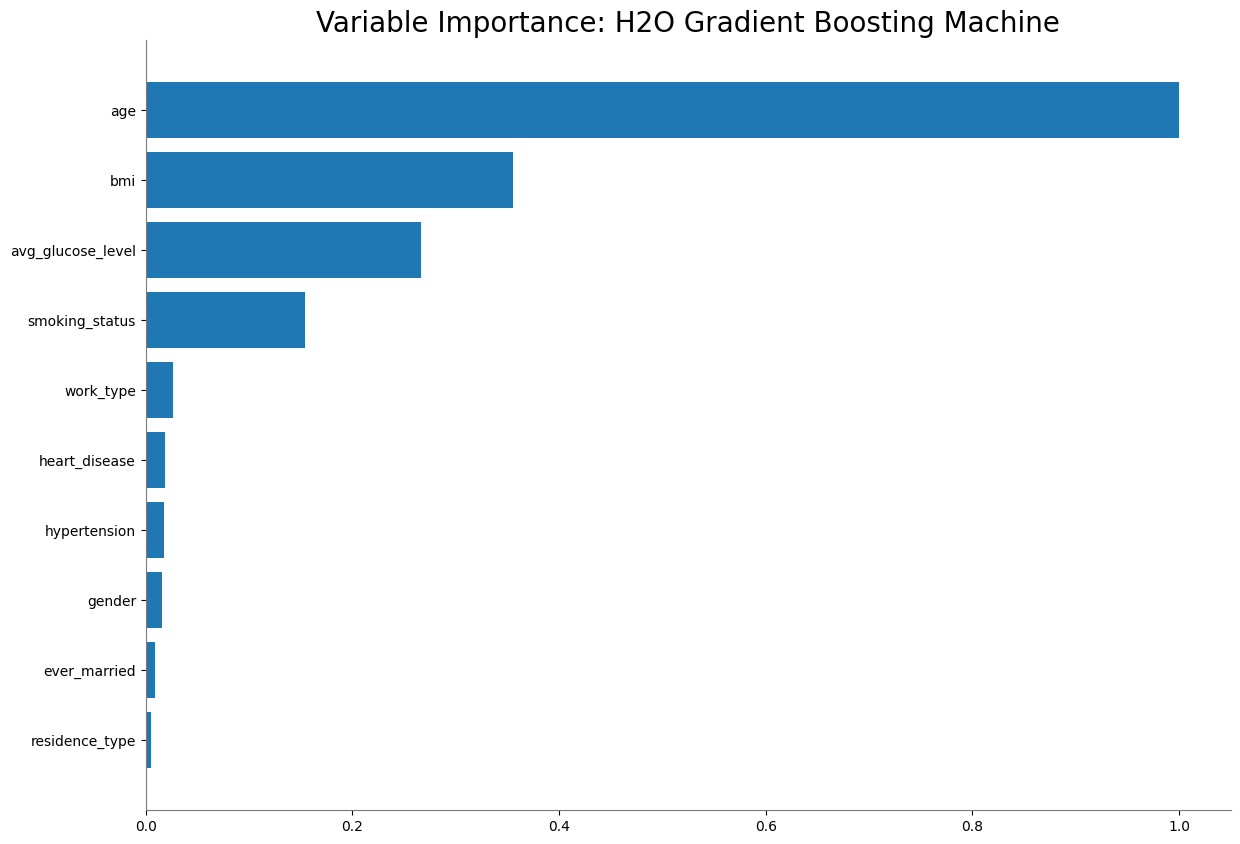

<Figure size 700x400 with 0 Axes>

In [44]:
# basic version
fit_1.varimp_plot()

### Dự đoán về dữ liệu đào tạo

gbm prediction progress: |███████████████████████████████████████████████████████| (done) 100%


/usr/local/lib/python3.12/dist-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


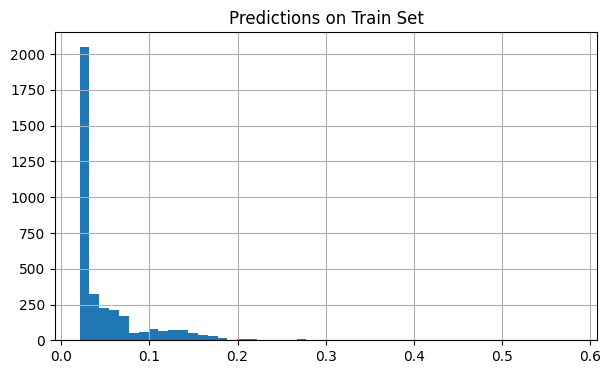

In [45]:
# predict on train set (extract probabilities only)
pred_train = fit_1.predict(train_hex)['p1']
pred_train = pred_train.as_data_frame().p1

# and plot
plt.hist(pred_train, bins=50)
plt.title('Predictions on Train Set')
plt.grid()
plt.show()

In [46]:
# check calibration
frequency_pred = sum(pred_train)
frequency_act = df_train.target.sum()
print('Predicted Frequency:', frequency_pred)
print('Actual Frequency   :', frequency_act)

Predicted Frequency: 184.40023228358382
Actual Frequency   : 184


# **Đánh giá trên Bộ kiểm tra**

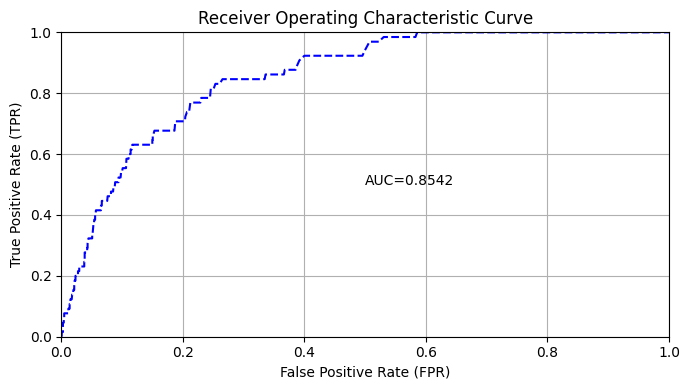

([0.0006872852233676976,
  0.0006872852233676976,
  0.0013745704467353953,
  0.002061855670103093,
  0.0027491408934707906,
  0.0027491408934707906,
  0.0027491408934707906,
  0.003436426116838488,
  0.004123711340206186,
  0.004123711340206186,
  0.004810996563573883,
  0.004810996563573883,
  0.005498281786941581,
  0.006185567010309278,
  0.006872852233676976,
  0.007560137457044674,
  0.008247422680412371,
  0.008934707903780068,
  0.010309278350515464,
  0.010996563573883162,
  0.01168384879725086,
  0.01168384879725086,
  0.012371134020618556,
  0.013058419243986255,
  0.013745704467353952,
  0.013745704467353952,
  0.01443298969072165,
  0.015120274914089347,
  0.015807560137457044,
  0.016494845360824743,
  0.01718213058419244,
  0.017869415807560136,
  0.019243986254295534,
  0.01993127147766323,
  0.021305841924398626,
  0.021305841924398626,
  0.021993127147766325,
  0.02268041237113402,
  0.02336769759450172,
  0.02336769759450172,
  0.024054982817869417,
  0.02474226804123

In [47]:
# calc performance on test test
perf_test = fit_1.model_performance(test_hex)

# ROC Curve - Test Set
perf_test.plot()

In [48]:
# confusion matrix using our manual threshold
conf_test_man = perf_test.confusion_matrix(thresholds=tt)
conf_test_man.show()

Could not find exact threshold 0.148; using closest threshold found 0.1480016916497603.


,0,1,Error,Rate
0,1401.0,54.0,0.0371,(54.0/1455.0)
1,50.0,15.0,0.7692,(50.0/65.0)
Total,1451.0,69.0,0.0684,(104.0/1520.0)


#### Khá tốt: 65 kết quả dương tính thực tế so với 69 kết quả dương tính dự đoán.

In [49]:
# calc accuracy for manual threshold:
conf_list_temp = conf_test_man.to_list()
n_matrix = sum(conf_list_temp[0]) + sum(conf_list_temp[1])
acc_t1_test = (conf_list_temp[0][0]+conf_list_temp[1][1]) / n_matrix
print('Accuracy:', np.round(acc_t1_test,6))

Accuracy: 0.931579


gbm prediction progress: |███████████████████████████████████████████████████████| (done) 100%


/usr/local/lib/python3.12/dist-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


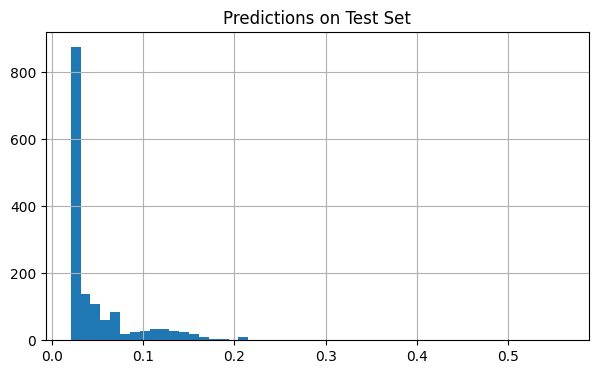

In [50]:
# predict on test set (extract probabilities only)
pred_test = fit_1.predict(test_hex)['p1']
pred_test = pred_test.as_data_frame().p1

# and plot
plt.hist(pred_test, bins=50)
plt.title('Predictions on Test Set')
plt.grid()
plt.show()

In [51]:
# connect prediction with data frame
df_test['prediction'] = pred_test

### Hiển thị ví dụ

In [52]:
# show most endangered patients (according to our model) in test set
df_high_20 = df_test.nlargest(20, columns='prediction')
df_high_20

,id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,target,age_bin,avg_glucose_level_bin,bmi_bin,prediction
475,17752,Male,76.0,0,1,Yes,Private,Urban,79.05,-99.0,Unknown,0,"(75.0, 82.0]","(73.8, 80.0]","(-100, 10]",0.561063
21,7356,Male,75.0,0,0,Yes,Private,Urban,104.72,-99.0,Unknown,1,"(65.0, 75.0]","(98.9, 108.5]","(-100, 10]",0.550400
553,1741,Male,77.0,0,0,Yes,Private,Urban,74.26,-99.0,formerly smoked,0,"(75.0, 82.0]","(73.8, 80.0]","(-100, 10]",0.545057
380,132,Female,80.0,0,0,Yes,Govt_job,Urban,84.86,-99.0,Unknown,0,"(75.0, 82.0]","(80.0, 85.6]","(-100, 10]",0.531739
686,1077,Male,77.0,0,1,Yes,Govt_job,Rural,106.03,-99.0,Unknown,0,"(75.0, 82.0]","(98.9, 108.5]","(-100, 10]",0.520791
14,15102,Male,78.0,1,0,Yes,Private,Urban,75.32,-99.0,formerly smoked,1,"(75.0, 82.0]","(73.8, 80.0]","(-100, 10]",0.517326
4,8213,Male,78.0,0,1,Yes,Private,Urban,219.84,-99.0,Unknown,1,"(75.0, 82.0]","(192.2, 271.7]","(-100, 10]",0.305811
1483,10995,Male,76.0,1,0,Yes,Private,Rural,267.60,30.5,never smoked,0,"(75.0, 82.0]","(192.2, 271.7]","(30, 35]",0.305160
92,4480,Male,76.0,0,0,Yes,Private,Rural,234.58,34.3,formerly smoked,0,"(75.0, 82.0]","(192.2, 271.7]","(30, 35]",0.285260
6,25226,Male,57.0,0,1,No,Govt_job,Urban,217.08,-99.0,Unknown,1,"(51.0, 57.0]","(192.2, 271.7]","(-100, 10]",0.280943


#### Kiểm tra hiệu chuẩn ở mức cao:

In [53]:
print('Actual cases in highest 20    :', df_high_20.target.sum())
print('Predicted cases in highest 20 :', np.round(df_high_20.prediction.sum(),2))

Actual cases in highest 20    : 5
Predicted cases in highest 20 : 6.69


In [54]:
# show least endangered patients (according to our model) in test set
df_low_20 = df_test.nsmallest(20, columns='prediction')
df_low_20

,id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,target,age_bin,avg_glucose_level_bin,bmi_bin,prediction
788,57904,Male,15.0,0,0,No,Private,Urban,190.13,20.7,never smoked,0,"(11.0, 20.0]","(124.2, 192.2]","(20, 25]",0.020934
67,46136,Male,14.0,0,0,No,Never_worked,Rural,161.28,19.1,Unknown,0,"(11.0, 20.0]","(124.2, 192.2]","(10, 20]",0.020988
83,55680,Male,13.0,0,0,No,children,Urban,114.84,18.3,Unknown,0,"(11.0, 20.0]","(108.5, 124.2]","(10, 20]",0.020988
98,42996,Female,36.0,0,0,No,Govt_job,Rural,126.82,23.3,never smoked,0,"(30.0, 38.0]","(124.2, 192.2]","(20, 25]",0.020988
118,56681,Female,22.0,0,0,No,Private,Urban,130.34,22.0,never smoked,0,"(20.0, 30.0]","(124.2, 192.2]","(20, 25]",0.020988
125,34376,Female,16.0,0,0,No,children,Rural,113.47,19.5,Unknown,0,"(11.0, 20.0]","(108.5, 124.2]","(10, 20]",0.020988
143,22622,Male,10.0,0,0,No,children,Rural,108.79,21.0,Unknown,0,"(-0.020000000000000004, 11.0]","(108.5, 124.2]","(20, 25]",0.020988
161,61408,Male,23.0,0,0,No,Never_worked,Urban,125.26,18.7,never smoked,0,"(20.0, 30.0]","(124.2, 192.2]","(10, 20]",0.020988
175,20364,Female,4.0,0,0,No,children,Urban,107.25,12.0,Unknown,0,"(-0.020000000000000004, 11.0]","(98.9, 108.5]","(10, 20]",0.020988
254,32554,Female,16.0,0,0,No,children,Rural,109.02,19.8,Unknown,0,"(11.0, 20.0]","(108.5, 124.2]","(10, 20]",0.020988


#### Kiểm tra hiệu chuẩn ở mức thấp:

In [55]:
print('Actual cases in lowest 20    :', df_low_20.target.sum())
print('Predicted cases in lowest 20 :', np.round(df_low_20.prediction.sum(),2))

Actual cases in lowest 20    : 0
Predicted cases in lowest 20 : 0.42
